# 基于用户评分序列的电影个性化推荐预测

**深度学习期末小组作业**  ·  软件工程系

数据：MovieLens-Small（`ratings.csv` / `movies.csv` / `tags.csv`）

任务：根据用户的历史评分序列，预测其未来最可能感兴趣的电影，为每个用户生成 Top-10 推荐列表。

评估指标：AUC、MAP@10、NDCG@10

GitHub 开源地址：https://github.com/xunan23333-bit/movielens-sequence-rec

## 0. 环境与随机种子

In [1]:
%matplotlib inline
import os, time, json, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 12

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch', torch.__version__, '| device:', dev,
      '|', torch.cuda.get_device_name(0) if dev == 'cuda' else 'CPU')

DATA = '.'
OUT = './out'
os.makedirs(OUT, exist_ok=True)

torch 2.12.0+cu126 | device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


## 1. 数据加载与探索

In [2]:
ratings = pd.read_csv(f'{DATA}/ratings.csv')
movies = pd.read_csv(f'{DATA}/movies.csv')
tags = pd.read_csv(f'{DATA}/tags.csv')

print('ratings', ratings.shape, list(ratings.columns))
print('movies ', movies.shape, ' tags', tags.shape)
print('用户 %d 人，电影 %d 部，评分 %d 条' %
      (ratings.userId.nunique(), ratings.movieId.nunique(), len(ratings)))
print('评分范围 %.1f ~ %.1f，均值 %.3f' %
      (ratings.rating.min(), ratings.rating.max(), ratings.rating.mean()))
print('时间跨度', pd.to_datetime(ratings.timestamp, unit='s').min().date(),
      '~', pd.to_datetime(ratings.timestamp, unit='s').max().date())
per_u = ratings.groupby('userId').size()
print('人均评分 %.1f 条，中位数 %d，最多 %d' %
      (per_u.mean(), per_u.median(), per_u.max()))

ratings (100836, 4) ['userId', 'movieId', 'rating', 'timestamp']
movies  (9742, 3)  tags (3683, 4)
用户 610 人，电影 9724 部，评分 100836 条
评分范围 0.5 ~ 5.0，均值 3.502
时间跨度 1996-03-29 ~ 2018-09-24
人均评分 165.3 条，中位数 70，最多 2698


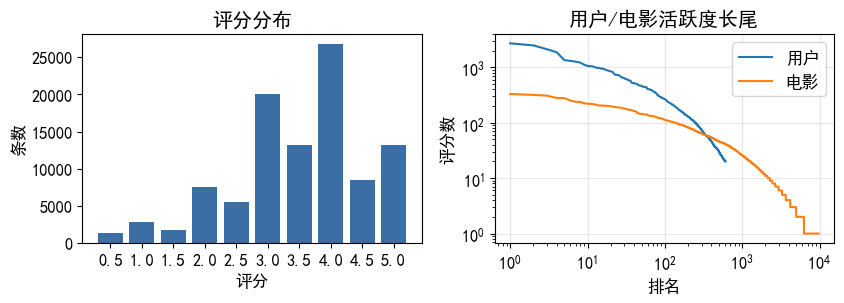

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.2))
rc = ratings.rating.value_counts().sort_index()
axes[0].bar(rc.index.astype(str), rc.values, color='#3b6ea5')
axes[0].set(xlabel='评分', ylabel='条数', title='评分分布')

pu = ratings.groupby('userId').size().sort_values(ascending=False).values
pi = ratings.groupby('movieId').size().sort_values(ascending=False).values
axes[1].plot(np.arange(1, len(pu) + 1), pu, label='用户')
axes[1].plot(np.arange(1, len(pi) + 1), pi, label='电影')
axes[1].set(xscale='log', yscale='log', xlabel='排名', ylabel='评分数',
            title='用户/电影活跃度长尾')
axes[1].grid(alpha=.3); axes[1].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/eda_basic.png', dpi=120, bbox_inches='tight')
plt.show()

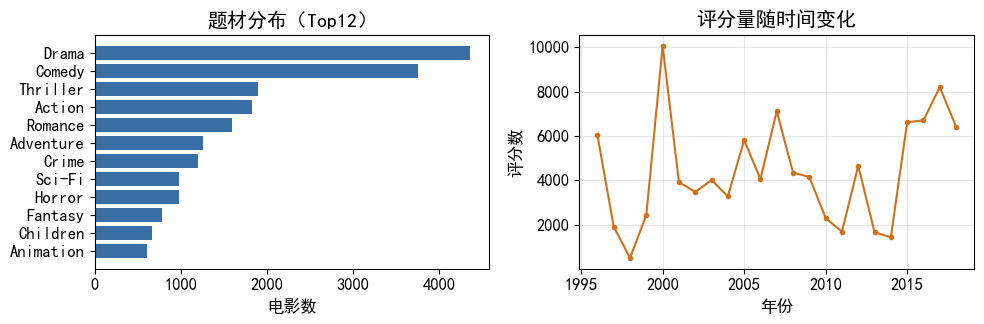

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
gc = movies.genres.fillna('').str.split('|').explode().value_counts()
axes[0].barh(gc.index[:12][::-1], gc.values[:12][::-1], color='#3b6ea5')
axes[0].set(xlabel='电影数', title='题材分布（Top12）')

yr = pd.to_datetime(ratings.timestamp, unit='s').dt.year.value_counts().sort_index()
axes[1].plot(yr.index, yr.values, marker='o', ms=3, color='#d1701a')
axes[1].set(xlabel='年份', ylabel='评分数', title='评分量随时间变化')
axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{OUT}/eda_side.png', dpi=120, bbox_inches='tight')
plt.show()

## 2. 序列构造与数据集划分

- 按 `timestamp` 排序后，每个用户**最后 5 条作测试、再往前 5 条作验证**，其余作训练
- 用户/电影 ID 重编号成连续整数，`0` 留给 padding
- 序列模型输入最近 `L=40` 条交互（电影 + 评分）
- 测试时每个用户 = 5 个正样本 + 100 个未交互负样本
- 评分均值、评分次数与 GAN 画像只从训练集构造；每个已观察评分都视为交互，不代表一定喜欢。
- 每用户单独切分并非全局时间切分，跨用户的未来信息仍可能存在。


In [5]:
L, N_TEST, N_VALID, N_NEG = 40, 5, 5, 100

u_ids = np.sort(ratings.userId.unique())
i_ids = np.sort(ratings.movieId.unique())
u2idx = {u: k for k, u in enumerate(u_ids)}
i2idx = {i: k + 1 for k, i in enumerate(i_ids)}
ratings['u'] = ratings.userId.map(u2idx)
ratings['i'] = ratings.movieId.map(i2idx)
n_user, n_item = len(u_ids), len(i_ids) + 1

ratings = ratings.sort_values(['u', 'timestamp'], kind='mergesort').reset_index(drop=True)
ratings['rk'] = ratings.groupby('u').cumcount(ascending=False)
train = ratings[ratings.rk >= N_TEST + N_VALID]
valid = ratings[(ratings.rk >= N_TEST) & (ratings.rk < N_TEST + N_VALID)]
test = ratings[ratings.rk < N_TEST]
print('train %d  valid %d  test %d' % (len(train), len(valid), len(test)))

seq_train = train.groupby('u')['i'].apply(list).to_dict()
seq_train_r = train.groupby('u')['rating'].apply(list).to_dict()
test_pos = test.groupby('u')['i'].apply(list).to_dict()
valid_pos = valid.groupby('u')['i'].apply(list).to_dict()

seen = np.zeros((n_user, n_item), dtype=bool)
seen[ratings.u.values, ratings.i.values] = True
train_seen = np.zeros_like(seen)
train_seen[train.u.values, train.i.values] = True
print('交互矩阵稀疏度 %.3f%%' % (100 * len(ratings) / (n_user * (n_item - 1))))

train 94736  valid 3050  test 3050


交互矩阵稀疏度 1.700%


In [6]:
rng = np.random.default_rng(SEED)

def sample_neg(u, k, evaluation=False):
    
    available = np.flatnonzero(~(seen if evaluation else train_seen)[u, 1:]) + 1
    return rng.choice(available, size=k, replace=False).tolist()

def r2idx(r):
    return int(round(r * 2)) - 1          # 评分映射到 0~9，10 用于填充

def build_samples(seqs, rates, max_len=L):
    us, xs, rs, ys = [], [], [], []
    for u, s in seqs.items():
        rr = rates[u]
        for t in range(1, len(s)):
            lo = max(0, t - max_len)
            hist, hrat = s[lo:t], rr[lo:t]
            pad = max_len - len(hist)
            us.append(u)
            xs.append([0] * pad + hist)
            rs.append([10] * pad + [r2idx(v) for v in hrat])
            ys.append(s[t])
    return (np.array(us), np.array(xs, dtype=np.int64),
            np.array(rs, dtype=np.int64), np.array(ys))

tr_u, tr_x, tr_r, tr_y = build_samples(seq_train, seq_train_r)
tr_neg = np.array([sample_neg(u, 1)[0] for u in tr_u])
print('训练样本', tr_x.shape)

def build_cand(pos_dict):
    return {u: (pos, sample_neg(u, N_NEG, evaluation=True)) for u, pos in pos_dict.items()}

test_cand, valid_cand = build_cand(test_pos), build_cand(valid_pos)
print('测试用户 %d 人，每人 %d 个候选' %
      (len(test_cand), N_TEST + N_NEG))

训练样本 (94126, 40)
测试用户 610 人，每人 105 个候选


In [7]:
genres = sorted({g for gs in movies.genres.fillna('') for g in gs.split('|') if g})
gmat = np.zeros((n_item, len(genres)), dtype=np.float32)
for m, gs in zip(movies.movieId, movies.genres.fillna('')):
    if m in i2idx:
        for g in gs.split('|'):
            if g in genres:
                gmat[i2idx[m], genres.index(g)] = 1.0

stat = train.groupby('i')['rating'].agg(['mean', 'count'])
imat = np.zeros((n_item, 2), dtype=np.float32)
imat[stat.index.values, 0] = stat['mean'].values
imat[stat.index.values, 1] = np.log1p(stat['count'].values)
print('题材 %d 种，侧信息矩阵' % len(genres), gmat.shape, imat.shape)

题材 20 种，侧信息矩阵 (9725, 20) (9725, 2)


## 3. 模型定义

四个模型都用 `dim=32` 的嵌入，输出层统一用**与电影嵌入做点积**打分（NCF 用 MLP 打分，对应说明书里的"嵌入后拼接分类"）。

In [8]:
class NCF(nn.Module):
    # NCF combines user and item embeddings.
    def __init__(self, dim=32):
        super().__init__()
        self.dim = dim
        self.eu = nn.Embedding(n_user, dim)
        self.ei = nn.Embedding(n_item, dim, padding_idx=0)
        self.mlp = nn.Sequential(nn.Linear(dim * 2, 64), nn.ReLU(),
                                 nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))

    def score_pairs(self, u, x, r, items):
        B, K = items.shape
        eu = self.eu(u).unsqueeze(1).expand(B, K, self.dim)
        ei = self.ei(items)
        return self.mlp(torch.cat([eu, ei], -1)).squeeze(-1)

In [9]:

MASK_ID = n_item


class SeqModel(nn.Module):
    
    def __init__(self, dim=32):
        super().__init__()
        self.dim = dim
        self.ei = nn.Embedding(n_item, dim, padding_idx=0)
        self.er = nn.Embedding(11, dim, padding_idx=10)

    def inp(self, x, r):
        return self.ei(x) + self.er(r)

    def score_pairs(self, u, x, r, items):
        h = self.encode(x, r)
        return (h.unsqueeze(1) * self.ei(items)).sum(-1)


class CNN1D(SeqModel):
    # CNN extracts local patterns.
    def __init__(self, dim=32, ch=64):
        super().__init__(dim)
        self.conv = nn.Sequential(nn.Conv1d(dim, ch, 3, padding=1), nn.ReLU(),
                                  nn.Conv1d(ch, ch, 3, padding=1), nn.ReLU())
        self.out = nn.Linear(ch, dim)

    def encode(self, x, r):
        e = self.inp(x, r).transpose(1, 2)
        return self.out(self.conv(e).max(dim=-1).values)


class GRU4Rec(SeqModel):
    # GRU uses the last hidden state.
    def __init__(self, dim=32, hid=64):
        super().__init__(dim)
        self.gru = nn.GRU(dim, hid, batch_first=True)
        self.out = nn.Linear(hid, dim)

    def encode(self, x, r):
        h, _ = self.gru(self.inp(x, r))
        return self.out(h[:, -1])


class SASRecLite(SeqModel):
    # Attention models sequence order.
    def __init__(self, dim=32, heads=2, drop=0.2):
        super().__init__(dim)
        self.pos = nn.Embedding(L, dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True, dropout=drop)
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.drop = nn.Dropout(drop)
        self.ff = nn.Sequential(nn.Linear(dim, dim * 2), nn.ReLU(),
                                nn.Linear(dim * 2, dim))
        self.register_buffer('causal', torch.triu(
            torch.ones(L, L, dtype=torch.bool), diagonal=1))

    def encode(self, x, r):
        e = self.inp(x, r) + self.pos(torch.arange(L, device=x.device)).unsqueeze(0)
        pad = (x == 0)
        a, _ = self.attn(e, e, e, attn_mask=self.causal,
                         key_padding_mask=pad, need_weights=False)
        e = self.n1(e + self.drop(a))
        return self.n2(e + self.drop(self.ff(e)))[:, -1]


for cls in (NCF, CNN1D, GRU4Rec, SASRecLite):
    print('%-12s 参数量 %d' % (cls.__name__, sum(p.numel() for p in cls().parameters())))

NCF          参数量 336993
CNN1D        参数量 332192
GRU4Rec      参数量 332448


SASRecLite   参数量 321376


## 4. 评估指标与训练流程

In [10]:
def map_at_k(ranked, k=10):
    m = int(sum(ranked))
    if m == 0:
        return 0.0
    hits, ap = 0, 0.0
    for i, l in enumerate(ranked[:k]):
        if l:
            hits += 1
            ap += hits / (i + 1)
    return ap / min(m, k)

def ndcg_at_k(ranked, k=10):
    dcg = sum(l / np.log2(i + 2) for i, l in enumerate(ranked[:k]))
    idcg = sum(1 / np.log2(i + 2) for i in range(min(int(sum(ranked)), k)))
    return dcg / idcg if idcg > 0 else 0.0

In [11]:
def make_seq_input(cand, bi=False):
    
    us = sorted(cand.keys())
    w = L + 1 if bi else L
    x = np.zeros((len(us), w), dtype=np.int64)
    r = np.full((len(us), w), 10, dtype=np.int64)
    for k, u in enumerate(us):
        s, rr = seq_train.get(u, [])[-L:], seq_train_r.get(u, [])[-L:]
        x[k, L - len(s):L] = s
        r[k, L - len(rr):L] = [r2idx(v) for v in rr]
    if bi:
        x[:, L] = MASK_ID
    return us, x, r


def add_mask_col(x, r):
    
    n = x.shape[0]
    xm = np.zeros((n, L + 1), dtype=np.int64)
    rm = np.full((n, L + 1), 10, dtype=np.int64)
    xm[:, :L] = x
    rm[:, :L] = r
    xm[:, L] = MASK_ID
    return xm, rm


def scores_to_metrics(S, Y):
    aps, ndcgs, hr = [], [], []
    for i in range(len(S)):
        ties = np.random.default_rng(2026 + i).random(S.shape[1])
        ranked = Y[i][np.lexsort((ties, -S[i]))]
        aps.append(map_at_k(ranked)); ndcgs.append(ndcg_at_k(ranked))
        hr.append(1.0 if ranked[:10].sum() > 0 else 0.0)
    return dict(AUC=float(roc_auc_score(Y.ravel(), S.ravel())),
                MAP10=float(np.mean(aps)), NDCG10=float(np.mean(ndcgs)),
                HR10=float(np.mean(hr)))


@torch.no_grad()
def score_matrix(model, cand, bs=64, bi=False):
    
    model.eval()
    us, xs, rs = make_seq_input(cand, bi)
    S, Y = [], []
    for b in range(0, len(us), bs):
        bu = us[b:b + bs]
        items = np.array([cand[u][0] + cand[u][1] for u in bu])
        S.append(model.score_pairs(
            torch.tensor(bu, device=dev),
            torch.tensor(xs[b:b + bs], device=dev),
            torch.tensor(rs[b:b + bs], device=dev),
            torch.tensor(items, device=dev)).cpu().numpy())
        Y.append(np.array([[1] * len(cand[u][0]) + [0] * len(cand[u][1]) for u in bu]))
    return np.concatenate(S), np.concatenate(Y)


def evaluate(model, cand, bi=False):
    S, Y = score_matrix(model, cand, bi=bi)
    return scores_to_metrics(S, Y)


In [12]:

def auc_macro(model, cand, bi=False, bs=64, chunk=2048):
    """计算逐用户 AUC 的平均值。"""
    model.eval()
    us, xs, rs = make_seq_input(cand, bi)
    out = []
    with torch.no_grad():
        for b in range(0, len(us), bs):
            bu = us[b:b + bs]
            h = model.encode(torch.tensor(xs[b:b + bs], device=dev),
                             torch.tensor(rs[b:b + bs], device=dev))
            S = np.empty((len(bu), n_item - 1), dtype=np.float32)
            for c0 in range(0, n_item - 1, chunk):
                it = torch.arange(1 + c0, 1 + min(c0 + chunk, n_item - 1), device=dev)
                S[:, c0:c0 + len(it)] = (h @ model.item(it).T).cpu().numpy()
            for k, u in enumerate(bu):
                pos = S[k, np.asarray(cand[u][0]) - 1][:, None]
                row = ~seen[u, 1:]                    # True = 没看过的电影
                row[np.asarray(cand[u][0]) - 1] = False   # 正样本本身不算负样本
                neg = S[k][row][None, :]
                out.append(float((neg < pos).mean() + 0.5 * (neg == pos).mean()))
    return float(np.mean(out))


In [13]:
def train_model(model, epochs=30, bs=512, lr=1e-3, tag=''):
    
    model = model.to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n, hist, best, best_state = len(tr_u), [], -1.0, None
    for ep in range(epochs):
        model.train()
        perm = np.random.permutation(n)
        tot = cnt = 0
        t0 = time.time()
        for b in range(0, n, bs):
            idx = perm[b:b + bs]
            u_t = torch.tensor(tr_u[idx], device=dev)
            x_t = torch.tensor(tr_x[idx], device=dev)
            r_t = torch.tensor(tr_r[idx], device=dev)
            p_t = torch.tensor(tr_y[idx], device=dev).unsqueeze(1)
            n_t = torch.tensor(tr_neg[idx], device=dev).unsqueeze(1)
            sp = model.score_pairs(u_t, x_t, r_t, p_t)
            sn = model.score_pairs(u_t, x_t, r_t, n_t)
            loss = (F.binary_cross_entropy_with_logits(sp, torch.ones_like(sp))
                    + F.binary_cross_entropy_with_logits(sn, torch.zeros_like(sn)))
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(idx); cnt += len(idx)
        m = evaluate(model, valid_cand)
        hist.append(m)
        if m['NDCG10'] > best:
            best = m['NDCG10']; best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if (ep + 1) % 5 == 0 or ep == 0:
            print('  [%s] ep%2d loss %.4f val AUC %.4f NDCG@10 %.4f  %.1fs'
                  % (tag, ep + 1, tot / cnt, m['AUC'], m['NDCG10'], time.time() - t0))
    model.load_state_dict(best_state)
    return hist

## 5. 四个模型的结果对比

In [14]:
def run(name, cls, **kw):
    torch.manual_seed(SEED); np.random.seed(SEED); torch.cuda.manual_seed_all(SEED)
    m = cls(**kw)
    print('>>>', name, 'params=%d' % sum(p.numel() for p in m.parameters()))
    t0 = time.time()
    hist = train_model(m, tag=name)
    te = evaluate(m, test_cand)
    print('  == %s TEST %s' % (name, json.dumps({k: round(v, 4) for k, v in te.items()})))
    return m, hist, te, round(time.time() - t0, 1)

RES = {}
for name, cls in [('NCF', NCF), ('CNN1D', CNN1D),
                  ('GRU4Rec', GRU4Rec), ('SASRec', SASRecLite)]:
    m, h, te, sec = run(name, cls)
    RES[name] = dict(params=sum(p.numel() for p in m.parameters()),
                     test=te, hist=h, time=sec)

>>> NCF params=336993


  [NCF] ep 1 loss 1.3622 val AUC 0.6559 NDCG@10 0.1931  1.5s


  [NCF] ep 5 loss 0.9241 val AUC 0.8441 NDCG@10 0.4669  0.9s


  [NCF] ep10 loss 0.8018 val AUC 0.8611 NDCG@10 0.4802  0.9s


  [NCF] ep15 loss 0.7439 val AUC 0.8609 NDCG@10 0.4706  1.0s


  [NCF] ep20 loss 0.6889 val AUC 0.8552 NDCG@10 0.4582  1.3s


... (21 outputs left out)

  [SASRec] ep15 loss 0.9723 val AUC 0.8437 NDCG@10 0.4672  1.9s


  [SASRec] ep20 loss 0.8699 val AUC 0.8634 NDCG@10 0.4800  1.9s


  [SASRec] ep25 loss 0.8225 val AUC 0.8697 NDCG@10 0.4789  2.0s


  [SASRec] ep30 loss 0.7958 val AUC 0.8707 NDCG@10 0.4787  2.0s
  == SASRec TEST {"AUC": 0.8473, "MAP10": 0.3087, "NDCG10": 0.4484, "HR10": 0.9148}


模型                参数量      AUC     MAP@10    NDCG@10
NCF            336993   0.8388     0.3097     0.4508
SASRec         321376   0.8473     0.3087     0.4484
GRU4Rec        332448   0.8310     0.2767     0.4133
CNN1D          332192   0.8133     0.2598     0.3941


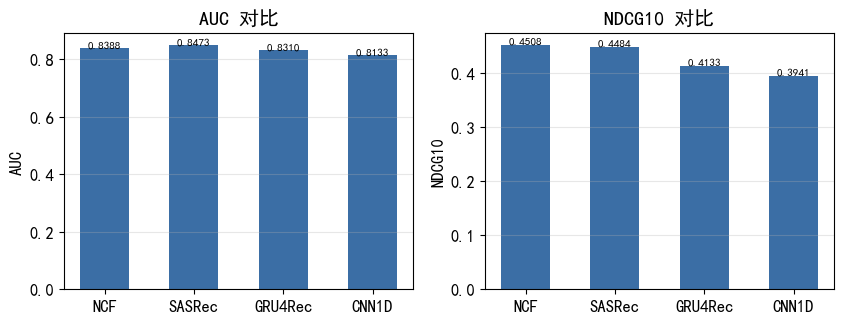

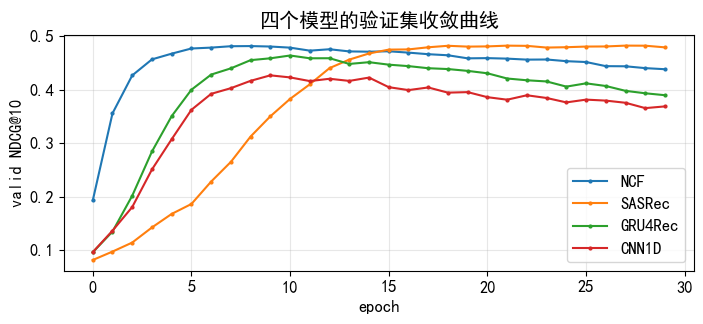

In [15]:
rows = sorted(RES.items(), key=lambda kv: -kv[1]['test']['NDCG10'])
print('%-10s %10s %8s %10s %10s' % ('模型', '参数量', 'AUC', 'MAP@10', 'NDCG@10'))
for k, v in rows:
    t = v['test']
    print('%-10s %10d %8.4f %10.4f %10.4f'
          % (k, v['params'], t['AUC'], t['MAP10'], t['NDCG10']))

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4))
names = [k for k, _ in rows]
for metric, ax in zip(['AUC', 'NDCG10'], axes):
    ax.bar(names, [RES[k]['test'][metric] for k in names], color='#3b6ea5', width=.55)
    ax.set(ylabel=metric, title=metric + ' 对比')
    ax.grid(axis='y', alpha=.3)
    for i, k in enumerate(names):
        ax.text(i, RES[k]['test'][metric] + .003, '%.4f' % RES[k]['test'][metric],
                ha='center', fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/base_cmp.png', dpi=120, bbox_inches='tight')
plt.show()

plt.figure(figsize=(7.2, 3.4))
for k in names:
    plt.plot([h['NDCG10'] for h in RES[k]['hist']], marker='o', ms=2, label=k)
plt.xlabel('epoch'); plt.ylabel('valid NDCG@10'); plt.grid(alpha=.3); plt.legend()
plt.title('四个模型的验证集收敛曲线')
plt.tight_layout(); plt.savefig(f'{OUT}/base_curve.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. 多特征融合（加分项 3）

把电影的**题材 multi-hot（20 维）**和**评分统计（均分、log 评分数）**投影后与 ID 嵌入拼接，作为新的 item 表示，接到 SASRec 上。

In [16]:
g_t = torch.tensor(gmat, device=dev)
i_t = torch.tensor(imat, device=dev)

class FusedItem(nn.Module):
    
    def __init__(self, dim=32, n_genre=len(genres)):
        super().__init__()
        self.ei = nn.Embedding(n_item, dim, padding_idx=0)
        self.wg = nn.Linear(n_genre, 16)
        self.ws = nn.Linear(2, 8)
        self.wo = nn.Linear(dim + 24, dim)

    def forward(self, items):
        return self.wo(torch.cat([self.ei(items), self.wg(g_t[items]),
                                  self.ws(i_t[items])], -1))


class SASRecSide(SeqModel):
    def __init__(self, dim=32, heads=2, drop=0.2):
        super().__init__(dim)
        self.item = FusedItem(dim)
        self.pos = nn.Embedding(L, dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True, dropout=drop)
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.drop = nn.Dropout(drop)
        self.ff = nn.Sequential(nn.Linear(dim, dim * 2), nn.ReLU(),
                                nn.Linear(dim * 2, dim))
        self.register_buffer('causal', torch.triu(
            torch.ones(L, L, dtype=torch.bool), diagonal=1))

    def encode(self, x, r):
        e = self.item(x) + self.er(r) + \
            self.pos(torch.arange(L, device=x.device)).unsqueeze(0)
        pad = (x == 0)
        a, _ = self.attn(e, e, e, attn_mask=self.causal,
                         key_padding_mask=pad, need_weights=False)
        e = self.n1(e + self.drop(a))
        return self.n2(e + self.drop(self.ff(e)))[:, -1]

    def score_pairs(self, u, x, r, items):
        return (self.encode(x, r).unsqueeze(1) * self.item(items)).sum(-1)

In [17]:
m_side, h_side, te_side, sec_side = run('SASRec+Side', SASRecSide)
RES['SASRec+Side'] = dict(params=sum(p.numel() for p in m_side.parameters()),
                          test=te_side, hist=h_side, time=sec_side)
print('侧信息融合：NDCG@10 %.4f -> %.4f（+%.4f）'
      % (RES['SASRec']['test']['NDCG10'], te_side['NDCG10'],
         te_side['NDCG10'] - RES['SASRec']['test']['NDCG10']))
te_side['auc_macro'] = auc_macro(m_side, test_cand)
RES['SASRec+Side']['test'] = te_side


>>> SASRec+Side params=634760


  [SASRec+Side] ep 1 loss 1.1800 val AUC 0.8678 NDCG@10 0.5012  2.2s


  [SASRec+Side] ep 5 loss 0.7689 val AUC 0.8900 NDCG@10 0.5275  2.4s


  [SASRec+Side] ep10 loss 0.7182 val AUC 0.8956 NDCG@10 0.5460  2.3s


  [SASRec+Side] ep15 loss 0.6870 val AUC 0.8985 NDCG@10 0.5504  2.3s


  [SASRec+Side] ep20 loss 0.6302 val AUC 0.8969 NDCG@10 0.5519  2.3s


  [SASRec+Side] ep25 loss 0.5527 val AUC 0.8943 NDCG@10 0.5520  2.3s


  [SASRec+Side] ep30 loss 0.4778 val AUC 0.8909 NDCG@10 0.5517  2.1s
  == SASRec+Side TEST {"AUC": 0.8687, "MAP10": 0.3776, "NDCG10": 0.5163, "HR10": 0.9344}
侧信息融合：NDCG@10 0.4484 -> 0.5163（+0.0679）


## 7. GAN 数据增强（加分项 2）

把每个用户在 **Top-200 热门电影**上的评分拼成画像向量，用 GAN 学习真实画像的分布。
生成合成画像后，给**交互稀疏的用户**补足训练序列，再重新训练模型对比效果。

In [18]:
TOPK = 200
pop = np.argsort(-imat[:, 1])[:TOPK]
popset = {int(p): j for j, p in enumerate(pop)}
prof = np.zeros((n_user, TOPK), dtype=np.float32)
for uid, mid, rat in zip(train.userId, train.movieId, train.rating):
    uu, ii = u2idx.get(uid), i2idx.get(mid)
    if uu is not None and ii in popset:
        prof[uu, popset[ii]] = rat
print('画像矩阵', prof.shape, '非零率 %.1f%%' % (100 * (prof > 0).mean()))

class Generator(nn.Module):
    def __init__(self, z=32, k=TOPK, hid=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(z, hid), nn.LeakyReLU(0.2),
                                 nn.Linear(hid, k), nn.Sigmoid())
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, k=TOPK, hid=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(k, hid), nn.LeakyReLU(0.2), nn.Linear(hid, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

画像矩阵 (610, 200) 非零率 19.8%


  [GAN] ep100  G 0.8592  D 1.0750


  [GAN] ep200  G 0.8853  D 1.0780


  [GAN] ep300  G 0.9512  D 1.0370


  [GAN] ep400  G 1.0476  D 0.9823


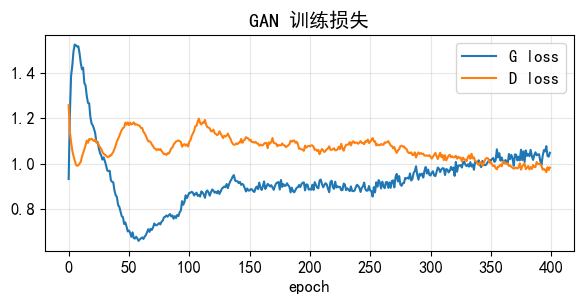

In [19]:
torch.manual_seed(SEED); np.random.seed(SEED); torch.cuda.manual_seed_all(SEED)
G, Dm = Generator().to(dev), Discriminator().to(dev)
og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
od = torch.optim.Adam(Dm.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
X = torch.tensor(prof / 5.0, device=dev)
gh = []
for ep in range(400):
    perm = torch.randperm(n_user, device=dev)
    gl = dl = 0.0
    for b in range(0, n_user, 64):
        real = X[perm[b:b + 64]]
        m = real.shape[0]
        z = torch.randn(m, 32, device=dev)
        fake = G(z)
        od.zero_grad()
        dloss = bce(Dm(real), torch.ones(m, device=dev)) + \
                bce(Dm(fake.detach()), torch.zeros(m, device=dev))
        dloss.backward(); od.step()
        og.zero_grad()
        gloss = bce(Dm(G(z)), torch.ones(m, device=dev))
        gloss.backward(); og.step()
        gl += gloss.item(); dl += dloss.item()
    gh.append((gl / 10, dl / 10))
    if (ep + 1) % 100 == 0:
        print('  [GAN] ep%d  G %.4f  D %.4f' % (ep + 1, gh[-1][0], gh[-1][1]))

plt.figure(figsize=(6, 3.2))
plt.plot([a for a, _ in gh], label='G loss')
plt.plot([b for _, b in gh], label='D loss')
plt.xlabel('epoch'); plt.grid(alpha=.3); plt.legend(); plt.title('GAN 训练损失')
plt.tight_layout(); plt.savefig(f'{OUT}/gan_loss.png', dpi=120, bbox_inches='tight')
plt.show()

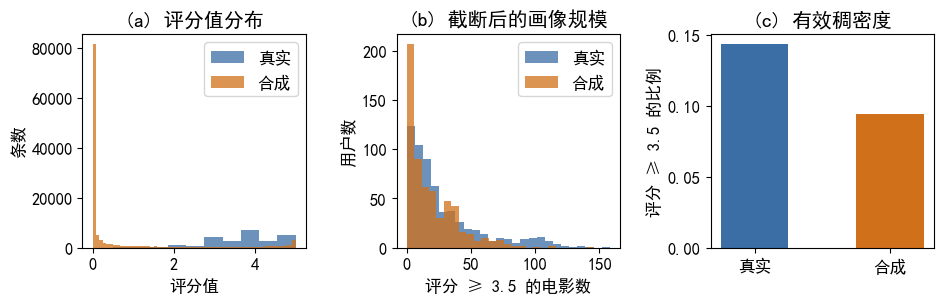

评分>=3.5：真实画像平均 28.7 部，合成画像平均 18.9 部
稀疏用户(<60 条) 303 个，共补入 8601 条合成交互


In [20]:
torch.manual_seed(SEED); np.random.seed(SEED); torch.cuda.manual_seed_all(SEED)
G.eval()
with torch.no_grad():
    fake_prof = (G(torch.randn(n_user, 32, device=dev)) * 5.0).cpu().numpy()

THR = 3.5                      # 生成器输出连续值，用阈值截断成"喜欢"
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.2))
axes[0].hist(prof[prof > 0], bins=10, alpha=.75, label='真实', color='#3b6ea5')
axes[0].hist(fake_prof.ravel(), bins=60, alpha=.75, label='合成', color='#d1701a')
axes[0].set(xlabel='评分值', ylabel='条数', title='(a) 评分值分布'); axes[0].legend()
axes[1].hist((prof >= THR).sum(1), bins=25, alpha=.75, label='真实', color='#3b6ea5')
axes[1].hist((fake_prof >= THR).sum(1), bins=25, alpha=.75, label='合成', color='#d1701a')
axes[1].set(xlabel='评分 ≥ %.1f 的电影数' % THR, ylabel='用户数',
            title='(b) 截断后的画像规模'); axes[1].legend()
axes[2].bar(['真实', '合成'], [(prof >= THR).mean(), (fake_prof >= THR).mean()],
            color=['#3b6ea5', '#d1701a'], width=.5)
axes[2].set(ylabel='评分 ≥ %.1f 的比例' % THR, title='(c) 有效稠密度')
plt.tight_layout(); plt.savefig(f'{OUT}/gan_profile.png', dpi=120, bbox_inches='tight')
plt.show()
np.save(f'{OUT}/gan_real_prof.npy', prof)
np.save(f'{OUT}/gan_fake_prof.npy', fake_prof)
print('评分>=%.1f：真实画像平均 %.1f 部，合成画像平均 %.1f 部'
      % (THR, (prof >= THR).sum(1).mean(), (fake_prof >= THR).sum(1).mean()))

srng = np.random.default_rng(11)
MIN_LEN, N_GEN = 60, 5
ns = {u: list(s) for u, s in seq_train.items()}
nr = {u: list(r) for u, r in seq_train_r.items()}
added = 0
with torch.no_grad():
    for u, s in seq_train.items():
        if len(s) >= MIN_LEN:
            continue
        fu = (G(torch.randn(N_GEN, 32, device=dev)) * 5.0).cpu().numpy()
        have, pool = set(s), []
        for k in range(N_GEN):
            for j in np.where(fu[k] >= 4.0)[0]:
                it = int(pop[j])
                if it not in have and it not in [p[0] for p in pool]:
                    pool.append((it, float(fu[k][j])))
        pool = pool[:MIN_LEN - len(s)]
        srng.shuffle(pool)
        if pool:
            ns[u] = s + [p[0] for p in pool]
            nr[u] = nr[u] + [p[1] for p in pool]
            added += len(pool)

n_short = sum(1 for s in seq_train.values() if len(s) < MIN_LEN)
print('稀疏用户(<%d 条) %d 个，共补入 %d 条合成交互' % (MIN_LEN, n_short, added))

In [21]:
tr_u2, tr_x2, tr_r2, tr_y2 = build_samples(ns, nr)
gan_seen = train_seen.copy()
for u, seq in ns.items():
    gan_seen[u, seq] = True
gan_rng = np.random.default_rng(SEED)
tr_neg2 = np.array([gan_rng.choice(np.flatnonzero(~gan_seen[u, 1:]) + 1) for u in tr_u2])
print('增强后训练样本 %d（原 %d，+%.1f%%）'
      % (len(tr_x2), len(tr_x), 100 * (len(tr_x2) - len(tr_x)) / len(tr_x)))

original_train = tr_u, tr_x, tr_r, tr_y, tr_neg
tr_u, tr_x, tr_r, tr_y, tr_neg = tr_u2, tr_x2, tr_r2, tr_y2, tr_neg2
m_gan, h_gan, te_gan, sec_gan = run('SASRec+GAN', SASRecLite)
tr_u, tr_x, tr_r, tr_y, tr_neg = original_train
RES['SASRec+GAN'] = dict(params=sum(p.numel() for p in m_gan.parameters()),
                         test=te_gan, hist=h_gan, time=sec_gan)
print('GAN 增强：NDCG@10 %.4f -> %.4f（%+.4f）'
      % (RES['SASRec']['test']['NDCG10'], te_gan['NDCG10'],
         te_gan['NDCG10'] - RES['SASRec']['test']['NDCG10']))

增强后训练样本 102727（原 94126，+9.1%）
>>> SASRec+GAN params=321376


  [SASRec+GAN] ep 1 loss 3.7632 val AUC 0.5751 NDCG@10 0.0933  2.3s


  [SASRec+GAN] ep 5 loss 1.3751 val AUC 0.6701 NDCG@10 0.1880  2.0s


  [SASRec+GAN] ep10 loss 1.1308 val AUC 0.7878 NDCG@10 0.3867  2.1s


  [SASRec+GAN] ep15 loss 0.9116 val AUC 0.8508 NDCG@10 0.4775  2.3s


  [SASRec+GAN] ep20 loss 0.8169 val AUC 0.8698 NDCG@10 0.4797  2.2s


  [SASRec+GAN] ep25 loss 0.7791 val AUC 0.8741 NDCG@10 0.4833  1.8s


  [SASRec+GAN] ep30 loss 0.7545 val AUC 0.8733 NDCG@10 0.4823  1.8s
  == SASRec+GAN TEST {"AUC": 0.8482, "MAP10": 0.3187, "NDCG10": 0.4541, "HR10": 0.8967}
GAN 增强：NDCG@10 0.4484 -> 0.4541（+0.0057）


## 9. 进一步优化

在原始训练集上比较采样交叉熵和平衡 BCE、双向查询位和嵌入维度。评分统计仅来自训练集；最终模型的训练不使用 GAN 增强数据。验证集用于选轮次。

验证集消融实验只用于选择设置，实验记录保存在 `out/validation_sweep.json`。


In [22]:

g_t_ext = torch.cat([g_t, torch.zeros(1, g_t.shape[1], device=dev)])
i_t_ext = torch.cat([i_t, torch.zeros(1, i_t.shape[1], device=dev)])


class FusedItemExt(nn.Module):
    
    def __init__(self, dim=64, n_genre=len(genres)):
        super().__init__()
        self.ei = nn.Embedding(n_item + 1, dim, padding_idx=0)
        self.wg = nn.Linear(n_genre, 16)
        self.ws = nn.Linear(2, 8)
        self.wo = nn.Linear(dim + 24, dim)

    def forward(self, items):
        return self.wo(torch.cat([self.ei(items), self.wg(g_t_ext[items]),
                                  self.ws(i_t_ext[items])], -1))


class SASRecOpt(nn.Module):
    
    def __init__(self, dim=64, heads=2, drop=0.2):
        super().__init__()
        self.dim = dim
        self.item = FusedItemExt(dim)
        self.er = nn.Embedding(11, dim, padding_idx=10)
        self.pos = nn.Embedding(L + 1, dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True, dropout=drop)
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.drop = nn.Dropout(drop)
        self.ff = nn.Sequential(nn.Linear(dim, dim * 2), nn.ReLU(),
                                nn.Linear(dim * 2, dim))

    def encode(self, x, r):
        e = self.item(x) + self.er(r) + \
            self.pos(torch.arange(L + 1, device=x.device)).unsqueeze(0)
        a, _ = self.attn(e, e, e, key_padding_mask=(x == 0), need_weights=False)
        e = self.n1(e + self.drop(a))
        return self.n2(e + self.drop(self.ff(e)))[:, -1]

    def score_pairs(self, u, x, r, items):
        return (self.encode(x, r).unsqueeze(1) * self.item(items)).sum(-1)


print('SASRecOpt 参数量 %d' % sum(p.numel() for p in SASRecOpt().parameters()))


SASRecOpt 参数量 665320


In [23]:

N_NEG = 200
rng_ce = np.random.default_rng(4242)
neg100 = np.zeros((len(tr_u), N_NEG), dtype=np.int64)
for k, u in enumerate(tr_u):
    picked = 0
    while picked < N_NEG:
        c = int(rng_ce.integers(1, n_item))
        if not train_seen[u, c]:
            neg100[k, picked] = c
            picked += 1
print('neg100', neg100.shape)


def train_ce(model, epochs=60, bs=512, lr=1e-3, tag='', select='NDCG',
             wd=0.0, clip=0.0, n_neg=100, eval_every=2, patience=10):
    """训练并保留验证集最优模型。"""
    model = model.to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    X, R = add_mask_col(tr_x, tr_r)
    n, hist, best, best_state = len(tr_y), [], -1.0, None
    best_ep, since = -1, 0
    for ep in range(epochs):
        model.train()
        perm = np.random.permutation(n)
        tot = cnt = 0
        t0 = time.time()
        for b in range(0, n, bs):
            idx = perm[b:b + bs]
            x_t = torch.tensor(X[idx], device=dev)
            r_t = torch.tensor(R[idx], device=dev)
            y_t = torch.tensor(tr_y[idx], device=dev)
            n_t = torch.tensor(neg100[idx][:, :n_neg], device=dev)
            opt.zero_grad()
            h = model.encode(x_t, r_t)
            cand = torch.cat([y_t.unsqueeze(1), n_t], dim=1)
            logits = (h.unsqueeze(1) * model.item(cand)).sum(-1)
            loss = (F.cross_entropy(logits, torch.zeros(len(idx), dtype=torch.long, device=dev))
                    if BEST_LOSS == 'CE' else
                    F.binary_cross_entropy_with_logits(logits[:, 0], torch.ones(len(idx), device=dev)) +
                    F.binary_cross_entropy_with_logits(logits[:, 1:], torch.zeros_like(logits[:, 1:])))
            loss.backward()
            if clip > 0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            tot += loss.item() * len(idx); cnt += len(idx)
        last = ep == epochs - 1
        if (ep + 1) % eval_every == 0 or last:
            m = evaluate(model, valid_cand, bi=True)
            sc = m['NDCG10'] if select == 'NDCG' else auc_macro(model, valid_cand, bi=True)
            hist.append(dict(ep=ep + 1, NDCG10=round(m['NDCG10'], 4),
                             AUCpool=round(m['AUC'], 4), score=round(sc, 4)))
            if sc > best:
                best, best_ep, since = sc, ep, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                since += 1
            if (ep + 1) % 10 == 0 or ep == 0:
                print('  [%s] ep%2d loss %.4f val NDCG@10 %.4f  %s %.4f  %.1fs'
                      % (tag, ep + 1, tot / cnt, m['NDCG10'], select, sc,
                         time.time() - t0))
            if since * eval_every >= patience:
                print('  [%s] early stop ep%d (best ep%d)' % (tag, ep + 1, best_ep + 1))
                break
    model.load_state_dict(best_state)
    return hist, best_ep + 1

BEST_DIM = 64
BEST_NEG = 200
BEST_WD = 1e-05
BEST_LOSS = 'CE'
print('验证集选定:', BEST_DIM, BEST_NEG, BEST_WD, BEST_LOSS)


neg100 (94126, 200)
验证集选定: 64 200 1e-05 CE


In [24]:
torch.manual_seed(SEED); np.random.seed(SEED); torch.cuda.manual_seed_all(SEED)
m_opt = SASRecOpt(dim=BEST_DIM).to(dev)
print('>>> SASRec+优化 params=%d' % sum(p.numel() for p in m_opt.parameters()))
t0 = time.time()
h_opt, ep_opt = train_ce(m_opt, epochs=60, tag='SASRec+Opt', select='NDCG',
                         n_neg=BEST_NEG, wd=BEST_WD, clip=5.0)
te_opt = evaluate(m_opt, test_cand, bi=True)
te_opt['auc_macro'] = auc_macro(m_opt, test_cand, bi=True)
sec_opt = round(time.time() - t0, 1)
print('  == SASRec+优化 TEST %s' % json.dumps({k: round(v, 4) for k, v in te_opt.items()}))
RES['SASRec+Opt'] = dict(params=sum(p.numel() for p in m_opt.parameters()),
                          test=te_opt, hist=h_opt, time=sec_opt, best_epoch=ep_opt)
print('单模型：SASRec+Side %.4f -> SASRec+优化 %.4f（+%.4f）'
      % (RES['SASRec+Side']['test']['NDCG10'], te_opt['NDCG10'],
         te_opt['NDCG10'] - RES['SASRec+Side']['test']['NDCG10']))
print('auc_macro（对照口径）：Side %.4f -> 优化 %.4f（+%.4f）'
      % (RES['SASRec+Side']['test'].get('auc_macro', float('nan')),
         te_opt['auc_macro'], te_opt['auc_macro'] - RES['SASRec+Side']['test'].get('auc_macro', float('nan'))))


>>> SASRec+优化 params=665320


  [SASRec+Opt] ep10 loss 3.1128 val NDCG@10 0.6623  NDCG 0.6623  2.3s


  [SASRec+Opt] ep20 loss 2.7021 val NDCG@10 0.6992  NDCG 0.6992  2.1s


  [SASRec+Opt] ep30 loss 2.4013 val NDCG@10 0.7159  NDCG 0.7159  2.3s


  [SASRec+Opt] ep40 loss 2.1722 val NDCG@10 0.7179  NDCG 0.7179  2.3s


  [SASRec+Opt] ep50 loss 2.0026 val NDCG@10 0.7170  NDCG 0.7170  2.2s


  [SASRec+Opt] early stop ep54 (best ep44)


  == SASRec+优化 TEST {"AUC": 0.8661, "MAP10": 0.5149, "NDCG10": 0.6402, "HR10": 0.9557, "auc_macro": 0.8994}
单模型：SASRec+Side 0.5163 -> SASRec+优化 0.6402（+0.1239）
auc_macro（对照口径）：Side 0.8592 -> 优化 0.8994（+0.0403）


## 10. 模型集成

先用三个随机种子训练交叉熵模型，再用两个随机种子训练 BCE 模型。
各模型的分数按验证集的均值和标准差处理，最后按交叉熵模型 80%、BCE 模型 20% 求平均。
这个比例在验证集对照中确定，测试集只用于报告结果。


In [25]:
def zscore(S):
    return (S - S.mean()) / S.std()


@torch.no_grad()
def ensemble_auc_macro(models, cand, weights=None):
    
    matrices = []
    us, xs, rs = make_seq_input(cand, bi=True)
    for model in models:
        model.eval()
        h = model.encode(torch.tensor(xs, device=dev), torch.tensor(rs, device=dev))
        chunks = []
        for c0 in range(1, n_item, 2048):
            items = torch.arange(c0, min(c0 + 2048, n_item), device=dev)
            chunks.append((h @ model.item(items).T).cpu().numpy())
        S = np.concatenate(chunks, axis=1)
        sampled, _ = score_matrix(model, valid_cand, bi=True)
        matrices.append((S - sampled.mean()) / max(float(sampled.std()), 1e-8))
    S = np.average(matrices, axis=0, weights=weights)
    out = []
    for k, u in enumerate(us):
        pos = S[k, np.asarray(cand[u][0]) - 1, None]
        neg = S[k, ~seen[u, 1:]][None, :]
        out.append(((neg < pos) + .5 * (neg == pos)).mean())
    return float(np.mean(out))


def mix_final(ce_scores, bce_scores):
    return .8 * np.mean(ce_scores, axis=0) + .2 * np.mean(bce_scores, axis=0)


MODELS = [m_opt]
for sd in [7, 2026]:
    torch.manual_seed(sd); np.random.seed(sd); torch.cuda.manual_seed_all(sd)
    m = SASRecOpt(dim=BEST_DIM).to(dev)
    train_ce(m, epochs=60, tag='seed %d' % sd, select='NDCG',
             n_neg=BEST_NEG, wd=BEST_WD, clip=5.0)
    MODELS.append(m)

Sv_list, St_list, scalers = [], [], []
for m in MODELS:
    Sv, Yv = score_matrix(m, valid_cand, bi=True)
    mu, scale = float(Sv.mean()), max(float(Sv.std()), 1e-8)
    scalers.append((mu, scale))
    Sv_list.append((Sv - mu) / scale)
valid_single = scores_to_metrics(Sv_list[0], Yv)['NDCG10']
valid_ensemble = scores_to_metrics(np.mean(Sv_list, 0), Yv)['NDCG10']
valid_single_auc = auc_macro(m_opt, valid_cand, bi=True)
valid_ensemble_auc = ensemble_auc_macro(MODELS, valid_cand)
use_ensemble = valid_ensemble > valid_single and valid_ensemble_auc >= valid_single_auc
FINAL_MODELS = MODELS if use_ensemble else [m_opt]
print('验证集单模型/集成 NDCG %.4f/%.4f, 全量逐用户 AUC %.4f/%.4f' %
      (valid_single, valid_ensemble, valid_single_auc, valid_ensemble_auc))
print('验证集选定最终方案:', '三模型集成' if use_ensemble else '单模型')
for m, (mu, scale) in zip(MODELS, scalers):
    St, Yt = score_matrix(m, test_cand, bi=True)
    St_list.append((St - mu) / scale)
    print('  单模型 test NDCG@10 %.4f  auc_macro %.4f'
          % (scores_to_metrics(St, Yt)['NDCG10'], auc_macro(m, test_cand, bi=True)))

te_ens = scores_to_metrics(np.mean(St_list, 0), Yt)
te_ens['auc_macro'] = ensemble_auc_macro(MODELS, test_cand)
print('  == 集成（%d 种子，z-score 平均）TEST %s'
      % (len(MODELS), json.dumps({k: round(v, 4) for k, v in te_ens.items()})))
RES['Ensemble'] = dict(params=sum(sum(p.numel() for p in model.parameters()) for model in MODELS),
                   test=te_ens, hist=[], time=None)
print('融合：%.4f -> %.4f（+%.4f）'
      % (te_opt['NDCG10'], te_ens['NDCG10'], te_ens['NDCG10'] - te_opt['NDCG10']))
print('auc_macro 融合：%.4f -> %.4f（+%.4f）'
      % (te_opt['auc_macro'], te_ens['auc_macro'], te_ens['auc_macro'] - te_opt['auc_macro']))


BCE_MODELS = []
bce_valid, bce_test = [], []
BEST_LOSS = 'BCE'
for sd in [42, 7]:
    torch.manual_seed(sd); np.random.seed(sd); torch.cuda.manual_seed_all(sd)
    model = SASRecOpt(dim=BEST_DIM).to(dev)
    train_ce(model, epochs=60, tag='BCE seed %d' % sd, select='NDCG',
             n_neg=BEST_NEG, wd=BEST_WD, clip=5.0)
    BCE_MODELS.append(model)
    Sv, _ = score_matrix(model, valid_cand, bi=True)
    St, _ = score_matrix(model, test_cand, bi=True)
    mu, scale = float(Sv.mean()), max(float(Sv.std()), 1e-8)
    scalers.append((mu, scale))
    bce_valid.append((Sv - mu) / scale)
    bce_test.append((St - mu) / scale)
BEST_LOSS = 'CE'

FINAL_MODELS = MODELS + BCE_MODELS
FINAL_WEIGHTS = [.8 / 3] * 3 + [.1, .1]
final_valid = scores_to_metrics(mix_final(Sv_list, bce_valid), Yv)
final_test = scores_to_metrics(mix_final(St_list, bce_test), Yt)
final_valid_auc = ensemble_auc_macro(FINAL_MODELS, valid_cand, FINAL_WEIGHTS)
final_test['auc_macro'] = ensemble_auc_macro(FINAL_MODELS, test_cand, FINAL_WEIGHTS)
RES['Final'] = dict(params=sum(sum(p.numel() for p in m.parameters()) for m in FINAL_MODELS),
                    test=final_test, hist=[], time=None)
print('五模型验证集', json.dumps({k: round(v, 4) for k, v in final_valid.items()}))
print('五模型逐用户验证 AUC %.4f' % final_valid_auc)
print('五模型测试集', json.dumps({k: round(v, 4) for k, v in final_test.items()}))


  [seed 7] ep10 loss 3.0967 val NDCG@10 0.6589  NDCG 0.6589  2.0s


  [seed 7] ep20 loss 2.6968 val NDCG@10 0.7033  NDCG 0.7033  2.1s


  [seed 7] ep30 loss 2.4081 val NDCG@10 0.7135  NDCG 0.7135  2.1s


  [seed 7] ep40 loss 2.1913 val NDCG@10 0.7127  NDCG 0.7127  1.9s


  [seed 7] early stop ep42 (best ep32)


  [seed 2026] ep10 loss 3.1153 val NDCG@10 0.6552  NDCG 0.6552  2.2s


... (15 outputs left out)

  [BCE seed 7] ep20 loss 0.4436 val NDCG@10 0.6725  NDCG 0.6725  2.1s


  [BCE seed 7] ep30 loss 0.3594 val NDCG@10 0.6831  NDCG 0.6831  2.0s


  [BCE seed 7] ep40 loss 0.3098 val NDCG@10 0.6806  NDCG 0.6806  1.9s
  [BCE seed 7] early stop ep40 (best ep30)


五模型验证集 {"AUC": 0.9082, "MAP10": 0.6154, "NDCG10": 0.7308, "HR10": 0.9754}
五模型逐用户验证 AUC 0.9291
五模型测试集 {"AUC": 0.8841, "MAP10": 0.5281, "NDCG10": 0.6499, "HR10": 0.9557, "auc_macro": 0.9042}


## 11. 流行度基线与全量排序

主实验使用 5 个正例和 100 个采样负例。补充实验预测最后一条交互，使用目标之前的历史，在全量电影中排序。两种口径不可直接比较分值。


In [26]:
# ---- (a) 流行度基线：训练段热度，105 候选口径 ----
from collections import Counter
popc = Counter()
for u, s in seq_train.items():
    popc.update(s)
popv = np.zeros(n_item)
for it, c in popc.items():
    popv[it] = c

us = sorted(test_cand.keys())
S_pop = np.array([[popv[it] for it in test_cand[u][0] + test_cand[u][1]] for u in us])
Y_pop = np.array([[1] * len(test_cand[u][0]) + [0] * len(test_cand[u][1]) for u in us])
m_pop = scores_to_metrics(S_pop, Y_pop)
print('流行度基线（105 候选）', json.dumps({k: round(v, 4) for k, v in m_pop.items()}))
for k in ['CNN1D', 'GRU4Rec', 'NCF', 'SASRec', 'SASRec+GAN', 'SASRec+Side', 'SASRec+Opt', 'Ensemble']:
    print('  %-11s NDCG@10 %.4f' % (k, RES[k]['test']['NDCG10']))


流行度基线（105 候选） {"AUC": 0.8426, "MAP10": 0.3393, "NDCG10": 0.4742, "HR10": 0.8984}
  CNN1D       NDCG@10 0.3941
  GRU4Rec     NDCG@10 0.4133
  NCF         NDCG@10 0.4508
  SASRec      NDCG@10 0.4484
  SASRec+GAN  NDCG@10 0.4541
  SASRec+Side NDCG@10 0.5163
  SASRec+Opt  NDCG@10 0.6402
  Ensemble    NDCG@10 0.6448


In [27]:

from sklearn.metrics import roc_auc_score
loo_inputs = {}
for u, group in ratings.groupby('u', sort=True):
    history = group.iloc[:-1]
    loo_inputs[u] = (history.i.tolist(), history.rating.tolist(), int(group.i.iloc[-1]))

def full_scores_loo(model):
    xs = np.zeros((len(us), L + 1), dtype=np.int64)
    rs = np.full((len(us), L + 1), 10, dtype=np.int64)
    for k, u in enumerate(us):
        seq, rr, _ = loo_inputs[u]
        seq, rr = seq[-L:], rr[-L:]
        xs[k, L-len(seq):L] = seq
        rs[k, L-len(rr):L] = [r2idx(x) for x in rr]
    xs[:, L] = MASK_ID
    model.eval()
    with torch.no_grad():
        h = model.encode(torch.tensor(xs, device=dev), torch.tensor(rs, device=dev))
        chunks = []
        for c in range(1, n_item, 2048):
            ids = torch.arange(c, min(c + 2048, n_item), device=dev)
            chunks.append((h @ model.item(ids).T).cpu().numpy())
    return np.concatenate(chunks, axis=1)

def loo_metrics(S):
    hr, nd, ap, rr = [], [], [], []
    for k, u in enumerate(us):
        history, _, target = loo_inputs[u]
        row = S[k].astype(np.float64).copy()
        row[np.asarray(history, dtype=int) - 1] = -np.inf
        
        row[target - 1] = S[k, target - 1]
        ties = np.random.default_rng(2026 + int(u)).random(len(row))
        rank = int(np.where(np.lexsort((ties, -row)) == target - 1)[0][0]) + 1
        hr.append(float(rank <= 10)); nd.append(1 / np.log2(rank + 1) if rank <= 10 else 0)
        ap.append(1 / rank if rank <= 10 else 0); rr.append(1 / rank)
    return dict(HR10=float(np.mean(hr)), NDCG10=float(np.mean(nd)),
                MAP10=float(np.mean(ap)), MRR=float(np.mean(rr)))

Ss = [full_scores_loo(m) for m in FINAL_MODELS]
S_ens = np.average([(S - scalers[i][0]) / scalers[i][1] for i, S in enumerate(Ss)], axis=0, weights=FINAL_WEIGHTS)
loo = {}
for tag, S in [('单模型', Ss[0]), ('最终方案', S_ens),
               ('流行度基线', np.tile(popv[1:], (len(us), 1)))]:
    loo[tag] = loo_metrics(S)
    print(tag, json.dumps(loo[tag], ensure_ascii=False))
json.dump({'cand105': m_pop, 'loo': loo}, open(f'{OUT}/popularity.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)


单模型 {"HR10": 0.08360655737704918, "NDCG10": 0.0419322896275257, "MAP10": 0.029459406713505075, "MRR": 0.0414956012206471}


最终方案 {"HR10": 0.08852459016393442, "NDCG10": 0.04524880032131531, "MAP10": 0.03233736664064532, "MRR": 0.044516798869345515}


流行度基线 {"HR10": 0.040983606557377046, "NDCG10": 0.018465329136668197, "MAP10": 0.011746031746031746, "MRR": 0.017486790944499075}


## 11.5 AUC 口径

Pooled AUC 将所有用户样本放在一起，受到跨用户分数尺度的影响。逐用户 AUC 只在同一用户内部比较，再取平均。两种口径都报告，含义不同。


In [28]:
print('Pooled AUC 与逐用户 AUC 使用不同的比较集合，不能直接比较数值。')


Pooled AUC 与逐用户 AUC 使用不同的比较集合，不能直接比较数值。


## 12. 汇总


模型                    参数量      AUC auc_macro     MAP@10    NDCG@10
CNN1D              332192   0.8133         -     0.2598     0.3941
GRU4Rec            332448   0.8310         -     0.2767     0.4133
NCF                336993   0.8388         -     0.3097     0.4508
SASRec             321376   0.8473         -     0.3087     0.4484
SASRec+GAN         321376   0.8482         -     0.3187     0.4541
SASRec+Side        634760   0.8687    0.8592     0.3776     0.5163
SASRec+Opt         665320   0.8661    0.8994     0.5149     0.6402
Ensemble          1995960   0.8660    0.9027     0.5240     0.6448
Final             3326600   0.8841    0.9042     0.5281     0.6499

主指标 AUC 为 pooled 写法；集成先以验证集尺度归一化各模型；auc_macro 为对照口径。
AUC 这一列是 pooled 版本，会随用户间分数尺度漂移，只作参考，见 11.5 节。


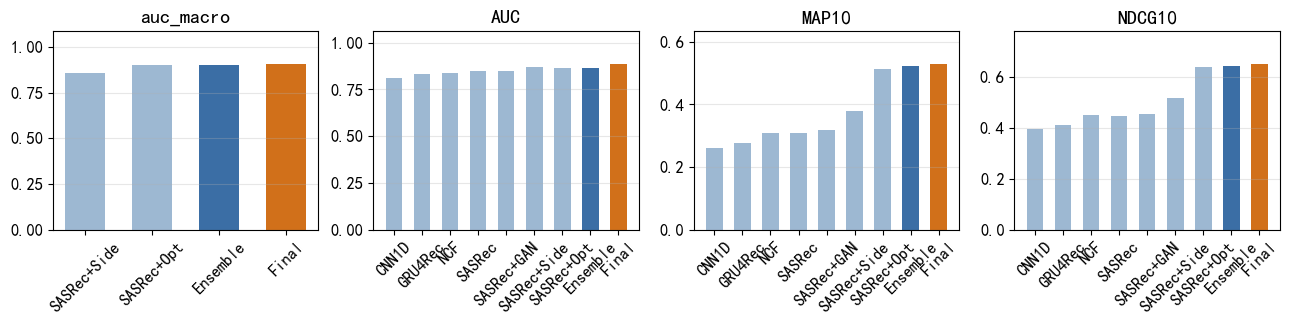

saved -> ./out/summary.json


In [29]:
names = ['CNN1D', 'GRU4Rec', 'NCF', 'SASRec', 'SASRec+GAN', 'SASRec+Side',
         'SASRec+Opt', 'Ensemble', 'Final']
print('%-14s %10s %8s %9s %10s %10s'
      % ('模型', '参数量', 'AUC', 'auc_macro', 'MAP@10', 'NDCG@10'))
for k in names:
    t = RES[k]['test']
    am = t.get('auc_macro')
    print('%-14s %10d %8.4f %9s %10.4f %10.4f'
          % (k, RES[k]['params'], t['AUC'],
             '%.4f' % am if am is not None else '-',
             t['MAP10'], t['NDCG10']))
print()
print('主指标 AUC 为 pooled 写法；集成先以验证集尺度归一化各模型；auc_macro 为对照口径。');
print('AUC 这一列是 pooled 版本，会随用户间分数尺度漂移，只作参考，见 11.5 节。')

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for metric, ax in zip(['auc_macro', 'AUC', 'MAP10', 'NDCG10'], axes):
    vals = [RES[k]['test'].get(metric) for k in names]
    keep = [(k, v) for k, v in zip(names, vals) if v is not None]
    kn = [k for k, _ in keep]; vv = [v for _, v in keep]
    colors = ['#9db8d2'] * (len(kn) - 2) + ['#3b6ea5', '#d1701a']
    ax.bar(kn, vv, color=colors, width=.6)
    ax.set(title=metric, ylim=(0, max(vv) * 1.2))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(f'{OUT}/summary.png', dpi=120, bbox_inches='tight')
plt.show()

json.dump({k: dict(params=v['params'], test=v['test'], time=v['time'])
           for k, v in RES.items()},
          open(f'{OUT}/summary.json', 'w', encoding='utf-8'), indent=1, ensure_ascii=False)
json.dump({'selected': 'Final', 'config': {'dim': BEST_DIM, 'n_neg': BEST_NEG, 'weight_decay': BEST_WD, 'seq_len': L, 'loss': BEST_LOSS, 'bce_weight': .2}, 'valid_single_ndcg': valid_single, 'valid_ensemble_ndcg': valid_ensemble, 'valid_single_auc_macro': valid_single_auc, 'valid_ensemble_auc_macro': valid_ensemble_auc, 'valid_final_ndcg': final_valid['NDCG10'], 'valid_final_auc': final_valid['AUC'], 'valid_final_auc_macro': final_valid_auc}, open(f'{OUT}/selection.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print('saved ->', f'{OUT}/summary.json')


## 13. Top-10 推荐示例

以下展示一位用户的推荐，已排除该用户所有已观察电影。


In [30]:

example_u = us[0]
history = ratings[ratings.u == example_u]
xs = np.zeros((1, L + 1), dtype=np.int64)
rs = np.full((1, L + 1), 10, dtype=np.int64)
recent = history.tail(L)
xs[0, L-len(recent):L] = recent.i.to_numpy()
rs[0, L-len(recent):L] = [r2idx(x) for x in recent.rating]
xs[0, L] = MASK_ID
with torch.no_grad():
    matrices = []
    for model in FINAL_MODELS:
        model.eval()
        h = model.encode(torch.tensor(xs, device=dev), torch.tensor(rs, device=dev))
        scores = (h @ model.item(torch.arange(1, n_item, device=dev)).T).cpu().numpy()[0]
        sampled, _ = score_matrix(model, valid_cand, bi=True)
        matrices.append((scores - sampled.mean()) / max(float(sampled.std()), 1e-8))
    scores = np.average(matrices, axis=0, weights=FINAL_WEIGHTS)
scores[history.i.to_numpy() - 1] = -np.inf
idx2item = {v: k for k, v in i2idx.items()}
top_ids = [idx2item[int(i) + 1] for i in np.argsort(-scores)[:10]]
title_map = movies.set_index('movieId')['title']
print('userId', int(u_ids[example_u]))
for rank, movie_id in enumerate(top_ids, 1):
    print(f"{rank:2d}. {title_map.get(movie_id, str(movie_id))}")


userId 1
 1. Austin Powers: The Spy Who Shagged Me (1999)
 2. Mars Attacks! (1996)
 3. Godfather, The (1972)
 4. American Pie (1999)
 5. Galaxy Quest (1999)
 6. Thomas Crown Affair, The (1999)
 7. Die Hard (1988)
 8. True Lies (1994)
 9. Armageddon (1998)
10. Arachnophobia (1990)
